<a href="https://colab.research.google.com/github/Alexxx0507/DEEP-LEARNING-PARA-PROCESAMIENTO-DE-IMAGENES-MEDICAS/blob/main/SEGMENTACION_BIO17_TECMERIDA(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="width: 100%; border-collapse: collapse; border: none; background-color: transparent;">
  <tr style="border: none;">
    <td style="width: 20%; border: none; text-align: center;">
      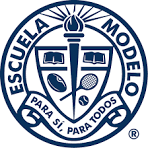
    </td>
    <td style="width: 60%; border: none; text-align: center;">
      <h2 style="margin: 0; font-family: sans-serif;">Tecnologico de Merida</h2>
      <h3 style="margin: 5px 0; color: #4a4a4a; font-family: sans-serif;">Taller: Deep Learning para Procesamiento de Imágenes Médicas</h3>
      <p style="margin: 15px 0 5px 0; font-size: 16px; font-family: sans-serif;">
        <b>Impartido por:</b><br>
        Br.Jorge Alejandro Chávez Gómez<br>
        Ing. Ismael Pérez Ruiz
      </p>
      <p style="margin: 0; font-style: italic; font-size: 14px; font-family: sans-serif;">
        Mérida, Yucatán — Noviembre 2026
      </p>
    </td>
    <td style="width: 20%; border: none; text-align: center;">
      <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQiyAYL5D1aU2YCON9_9-Y7IrNbXvE4d5inz0zvPzJQwA&s" alt="Logo HRAEPY" width="130">
    </td>
  </tr>
</table>
<hr style="border: 1px solid #ccc;">

## Segmentación del bazo en tomografía computarizada (CT)

En este notebook vamos a entrenar, desde cero, una red **U-Net** que segmenta el **bazo** en tomografías de abdomen.

**Dataset:** *Task09_Spleen* del [Medical Segmentation Decathlon](http://medicaldecathlon.com/) — 41 tomografías 3D con el bazo anotado por radiólogos (1.5 GB, licencia abierta CC BY-SA 4.0). El código lo descarga solo.

**Qué vamos a hacer**
1. Descargar los datos y entender cómo es una tomografía (volumen 3D, unidades Hounsfield, ventanas)
2. Preprocesar: aplicar la ventana, reducir el tamaño y separar **por paciente**
3. Probar un método clásico (umbral de intensidad) como punto de comparación
4. Construir una U-Net 2D que trabaja corte por corte
5. Entrenarla con pérdida Dice + BCE
6. Evaluar con Dice **por paciente en 3D**, ver las predicciones y calcular el volumen del bazo






##**1. CARGA DE ARCHIVOS**




In [ ]:
import os, glob, random, shutil, subprocess, sys, tarfile, urllib.request

import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

try:
    import nibabel as nib          # librería para leer archivos NIfTI (.nii.gz)
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "nibabel"])
    import nibabel as nib

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)
if device.type == "cpu":
    print("OJO: no hay GPU activa. Actívala en 'Entorno de ejecución' para entrenar más rápido.")

Dispositivo: cuda


# **2. DESCARGA DEL DATASET**

## ¿Cómo es una tomografía?

Tres ideas clave antes de tocar una red neuronal:

- **Es un volumen 3D**, no una foto: una pila de cortes axiales. Cada elemento es un *vóxel* con tamaño físico en milímetros.
- **Los valores están en unidades Hounsfield (HU)**, una escala física: aire ≈ −1000, grasa ≈ −100, agua = 0, tejidos blandos entre 20 y 150 aprox., hueso > 300.
- **La ventana**: el rango completo (−1000 a más de 1000 HU) no cabe en una escala de grises útil. Los radiólogos eligen un rango según lo que quieren ver. Para abdomen se usa centro 40 HU y ancho 400 HU, es decir, de −160 a 240 HU.

In [ ]:
URL = "https://msd-for-monai.s3-us-west-2.amazonaws.com/Task09_Spleen.tar"
TAR = "Task09_Spleen.tar"
RAIZ = "datos"

def buscar_carpeta(nombre):
    rutas = [p for p in glob.glob(os.path.join(RAIZ, "**", nombre), recursive=True) if os.path.isdir(p)]
    return rutas[0] if rutas else None

def descargar():
    if os.path.exists(TAR) and os.path.getsize(TAR) > 1e9:
        print("El archivo ya estaba descargado.")
        return
    print("Descargando 1.5 GB (suele tardar de 1 a 3 minutos)...")
    if shutil.which("wget"):
        subprocess.run(["wget", "-q", "-c", URL, "-O", TAR], check=True)
    else:
        urllib.request.urlretrieve(URL, TAR)
    print("Listo: %.2f GB" % (os.path.getsize(TAR) / 1e9))

if buscar_carpeta("labelsTr") is None:
    descargar()
    print("Descomprimiendo...")
    with tarfile.open(TAR) as t:
        # El .tar trae archivos ocultos de macOS (empiezan con "._"): los saltamos
        miembros = [m for m in t.getmembers()
                    if ("imagesTr" in m.name or "labelsTr" in m.name)
                    and not os.path.basename(m.name).startswith(".")]
        try:
            t.extractall(RAIZ, members=miembros, filter="data")
        except TypeError:               # versiones antiguas de Python no tienen 'filter'
            t.extractall(RAIZ, members=miembros)

DIR_IMG, DIR_MASK = buscar_carpeta("imagesTr"), buscar_carpeta("labelsTr")
assert DIR_IMG and DIR_MASK, "No encontré las carpetas imagesTr / labelsTr"

pacientes = sorted(
    f for f in os.listdir(DIR_MASK)
    if f.endswith(".nii.gz") and not f.startswith(".") and os.path.exists(os.path.join(DIR_IMG, f))
)
print(f"{len(pacientes)} tomografías con máscara en {DIR_IMG}")

Descargando 1.5 GB (suele tardar de 1 a 3 minutos)...
Listo: 1.61 GB
Descomprimiendo...
41 tomografías con máscara en datos/Task09_Spleen/imagesTr


Paciente: spleen_10.nii.gz
Forma del volumen (cortes, alto, ancho): (55, 512, 512)
Tamaño del vóxel (mm): (0.98, 0.98, 5.0)
Rango de valores: -1024 a 3072 HU
El bazo ocupa el 0.37% de los vóxeles y aparece en 17 de 55 cortes


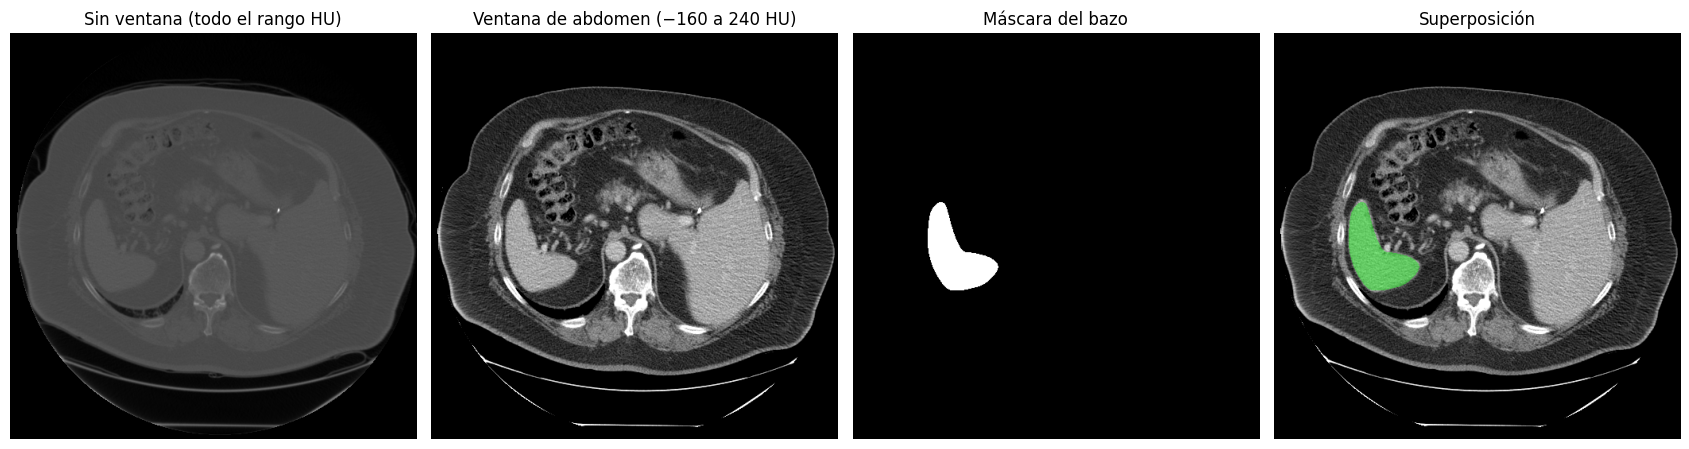

In [ ]:
def cargar_volumen(nombre):
    """Devuelve el CT en HU con forma (cortes, alto, ancho), la máscara (igual forma) y el tamaño del vóxel en mm."""
    nii = nib.load(os.path.join(DIR_IMG, nombre))
    ct = nii.get_fdata(dtype=np.float32)
    mask = np.asarray(nib.load(os.path.join(DIR_MASK, nombre)).dataobj).astype(np.uint8)
    # nibabel entrega los ejes como (X, Y, Z). Giramos y reordenamos para tener (Z, fila, columna)
    # con la orientación axial habitual (columna vertebral abajo).
    ct = np.rot90(ct, axes=(0, 1)).transpose(2, 0, 1)
    mask = np.rot90(mask, axes=(0, 1)).transpose(2, 0, 1)
    zooms = tuple(float(v) for v in nii.header.get_zooms()[:3])
    return np.ascontiguousarray(ct), np.ascontiguousarray(mask), zooms

def ventana(hu, centro=40, ancho=400):
    """Aplica una ventana de visualización y lleva el resultado al rango [0, 1]."""
    lo, hi = centro - ancho / 2, centro + ancho / 2
    return np.clip((hu - lo) / (hi - lo), 0, 1)

def superponer(gris, mask, color=(0, 255, 0), alfa=0.4):
    """Pinta la máscara semitransparente sobre un corte en escala de grises (uint8)."""
    out = np.stack([gris] * 3, axis=-1).astype(np.float32)
    out[mask > 0] = (1 - alfa) * out[mask > 0] + alfa * np.array(color, dtype=np.float32)
    return out.astype(np.uint8)

ct, mask, zooms = cargar_volumen(pacientes[0])
print("Paciente:", pacientes[0])
print("Forma del volumen (cortes, alto, ancho):", ct.shape)
print("Tamaño del vóxel (mm):", tuple(round(z, 2) for z in zooms))
print(f"Rango de valores: {ct.min():.0f} a {ct.max():.0f} HU")
print(f"El bazo ocupa el {100 * mask.mean():.2f}% de los vóxeles y aparece en "
      f"{int(mask.any(axis=(1, 2)).sum())} de {len(mask)} cortes")

k = int(mask.sum(axis=(1, 2)).argmax())      # el corte donde el bazo se ve más grande
v8 = (ventana(ct[k]) * 255).astype(np.uint8)
fig, ax = plt.subplots(1, 4, figsize=(17, 4.6))
ax[0].imshow(ct[k], cmap="gray"); ax[0].set_title("Sin ventana (todo el rango HU)")
ax[1].imshow(v8, cmap="gray"); ax[1].set_title("Ventana de abdomen (−160 a 240 HU)")
ax[2].imshow(mask[k], cmap="gray"); ax[2].set_title("Máscara del bazo")
ax[3].imshow(superponer(v8, mask[k])); ax[3].set_title("Superposición")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

# **3. PREPROCESAMIENTO**

Para cada tomografía:
1. Aplicamos la **ventana de abdomen** y guardamos el resultado en 8 bits (0–255).
2. Reducimos cada corte a **256×256** para que el entrenamiento sea rápido.
3. Guardamos el volumen de cada vóxel en mililitros (lo usaremos al final para medir el bazo).

Después separamos en entrenamiento, validación y prueba **por paciente**. Esto es fundamental en imagen médica: los cortes vecinos de un mismo paciente son casi idénticos, y si se mezclan entre entrenamiento y prueba el resultado sale artificialmente alto (*fuga de datos*).

In [ ]:
TAM = 256

def reducir(vol, tam=TAM):
    """Reduce cada corte de (Z, H, W) a (Z, tam, tam) promediando bloques de píxeles."""
    z, h, w = vol.shape
    if h == w and h % tam == 0:
        f = h // tam
        return vol.reshape(z, tam, f, tam, f).mean(axis=(2, 4))
    from skimage.transform import resize          # caso general, por si algún volumen no es 512x512
    return resize(vol, (z, tam, tam), order=1, anti_aliasing=True, preserve_range=True)

def preprocesar(nombre):
    ct, mask, zooms = cargar_volumen(nombre)
    z, h, w = ct.shape
    img = np.round(reducir(ventana(ct)) * 255).astype(np.uint8)
    m = (reducir(mask.astype(np.float32)) > 0.5).astype(np.uint8)
    ml_por_voxel = zooms[0] * zooms[1] * zooms[2] * (h / TAM) * (w / TAM) / 1000.0   # mm³ -> mL
    return {"img": img, "mask": m, "ml": ml_por_voxel}

datos = {p: preprocesar(p) for p in tqdm(pacientes, desc="Preprocesando")}

# División por paciente: 70% entrenamiento, 15% validación, 15% prueba
mezcla = pacientes.copy()
random.Random(SEED).shuffle(mezcla)
n_eval = max(1, round(0.15 * len(mezcla)))
pac_test = mezcla[:n_eval]
pac_val = mezcla[n_eval : 2 * n_eval]
pac_train = mezcla[2 * n_eval :]

total_cortes = sum(len(d["img"]) for d in datos.values())
print(f"Pacientes -> entrenamiento: {len(pac_train)} | validación: {len(pac_val)} | prueba: {len(pac_test)}")
print(f"Cortes en total: {total_cortes}")

Preprocesando:   0%|          | 0/41 [00:00<?, ?it/s]

Pacientes -> entrenamiento: 29 | validación: 6 | prueba: 6
Cortes en total: 3650


## **4. ANTES DE COMENZAR... COMPAREMOS...**

Antes de usar redes neuronales conviene preguntarse: ¿no basta con quedarse con los píxeles que tienen "la intensidad del bazo"?

Hacemos la prueba de forma justa: medimos el rango de intensidades del bazo en los pacientes de **entrenamiento** (percentiles 5 a 95) y lo aplicamos a los de **prueba**.

La métrica que usaremos en todo el taller es el **coeficiente Dice**:

$$\text{Dice} = \frac{2\,|A \cap B|}{|A| + |B|}$$

Vale 1 si la predicción coincide exactamente con la máscara y 0 si no se tocan.

Rango de intensidad del bazo (en la imagen de 0 a 255): 123 a 197
Dice promedio con umbral en los pacientes de prueba: 0.053


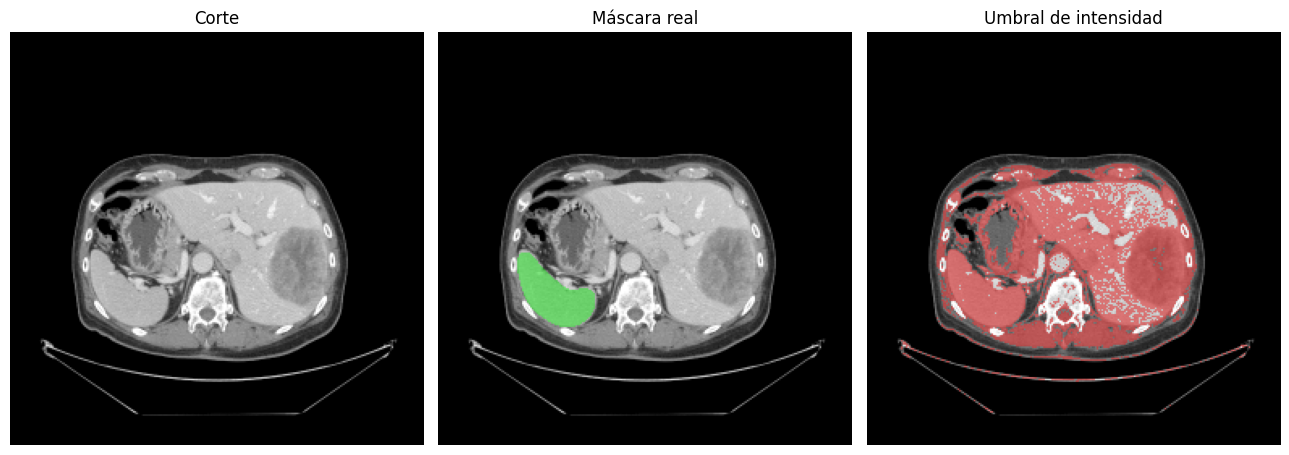

In [ ]:
def dice_np(pred, real, eps=1e-7):
    pred, real = pred.astype(bool), real.astype(bool)
    return (2 * (pred & real).sum() + eps) / (pred.sum() + real.sum() + eps)

intensidades = np.concatenate([datos[p]["img"][datos[p]["mask"] > 0] for p in pac_train])
lo, hi = np.percentile(intensidades, [5, 95])
print(f"Rango de intensidad del bazo (en la imagen de 0 a 255): {lo:.0f} a {hi:.0f}")

def segmentar_umbral(img):
    return ((img >= lo) & (img <= hi)).astype(np.uint8)

dice_umbral = np.array([dice_np(segmentar_umbral(datos[p]["img"]), datos[p]["mask"]) for p in pac_test])
print(f"Dice promedio con umbral en los pacientes de prueba: {dice_umbral.mean():.3f}")

p = pac_test[0]
k = int(datos[p]["mask"].sum(axis=(1, 2)).argmax())
img, mask = datos[p]["img"][k], datos[p]["mask"][k]
fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("Corte")
ax[1].imshow(superponer(img, mask)); ax[1].set_title("Máscara real")
ax[2].imshow(superponer(img, segmentar_umbral(img), color=(255, 0, 0))); ax[2].set_title("Umbral de intensidad")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

## **5. DATASET DE CORTES, USANDO PYTORCH**

Entrenamos una U-Net **2D**: cada corte axial es un ejemplo. Dos decisiones:

- **Balance:** la mayoría de los cortes no contiene bazo. Usamos todos los cortes con bazo y una cantidad igual de cortes sin bazo elegidos al azar. Los cortes vacíos importan: le enseñan a la red a no inventar bazo donde no lo hay.
- **Aumento de datos:** pequeños desplazamientos y cambios de brillo y contraste. **No usamos volteos**: el bazo siempre está del mismo lado del cuerpo, y voltear la imagen crearía una anatomía que no existe.

In [ ]:
class CortesDataset(Dataset):
    def __init__(self, lista_pacientes, aumentar=False, negativos_por_positivo=1.0):
        rng = np.random.default_rng(SEED)
        imgs, masks = [], []
        for p in lista_pacientes:
            m = datos[p]["mask"]
            tiene_bazo = m.any(axis=(1, 2))
            con, sin = np.where(tiene_bazo)[0], np.where(~tiene_bazo)[0]
            n_sin = min(len(sin), int(len(con) * negativos_por_positivo))
            elegidos = np.sort(np.concatenate([con, rng.choice(sin, n_sin, replace=False)])).astype(int)
            imgs.append(datos[p]["img"][elegidos])
            masks.append(m[elegidos])
        self.imgs = np.concatenate(imgs)       # (N, H, W) uint8
        self.masks = np.concatenate(masks)     # (N, H, W) uint8
        self.aumentar = aumentar

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        x = torch.from_numpy(self.imgs[i]).unsqueeze(0).float() / 255.0    # (1, H, W) en [0, 1]
        y = torch.from_numpy(self.masks[i]).unsqueeze(0).float()           # (1, H, W) en {0, 1}
        if self.aumentar:
            # Desplazamiento aleatorio de hasta 16 píxeles: rellenamos con ceros y recortamos
            d = 16
            x, y = F.pad(x, (d, d, d, d)), F.pad(y, (d, d, d, d))
            fila, col = random.randint(0, 2 * d), random.randint(0, 2 * d)
            x = x[:, fila : fila + TAM, col : col + TAM]
            y = y[:, fila : fila + TAM, col : col + TAM]
            # Cambio leve de contraste y brillo
            x = (x * random.uniform(0.9, 1.1) + random.uniform(-0.05, 0.05)).clamp(0, 1)
        return x, y

ds_train = CortesDataset(pac_train, aumentar=True)
BATCH = 16
dl_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True, drop_last=True)

x, y = next(iter(dl_train))
print(f"Cortes de entrenamiento: {len(ds_train)}")
print("Lote de imágenes:", tuple(x.shape), "| lote de máscaras:", tuple(y.shape))

Cortes de entrenamiento: 1425
Lote de imágenes: (16, 1, 256, 256) | lote de máscaras: (16, 1, 256, 256)


## **6. PROGRAMEMOS LA U-NET**

La U-Net tiene tres partes:

- **Encoder** (baja): convoluciones + *max pooling*. Va reduciendo la resolución y aprendiendo *qué* hay en la imagen.
- **Decoder** (sube): convoluciones transpuestas que recuperan la resolución para decir *dónde* está.
- **Conexiones de salto**: copian los mapas del encoder al decoder en cada nivel, para no perder los detalles finos de los bordes.

La entrada tiene **1 canal** (escala de grises) y la salida también: un valor (*logit*) por píxel.


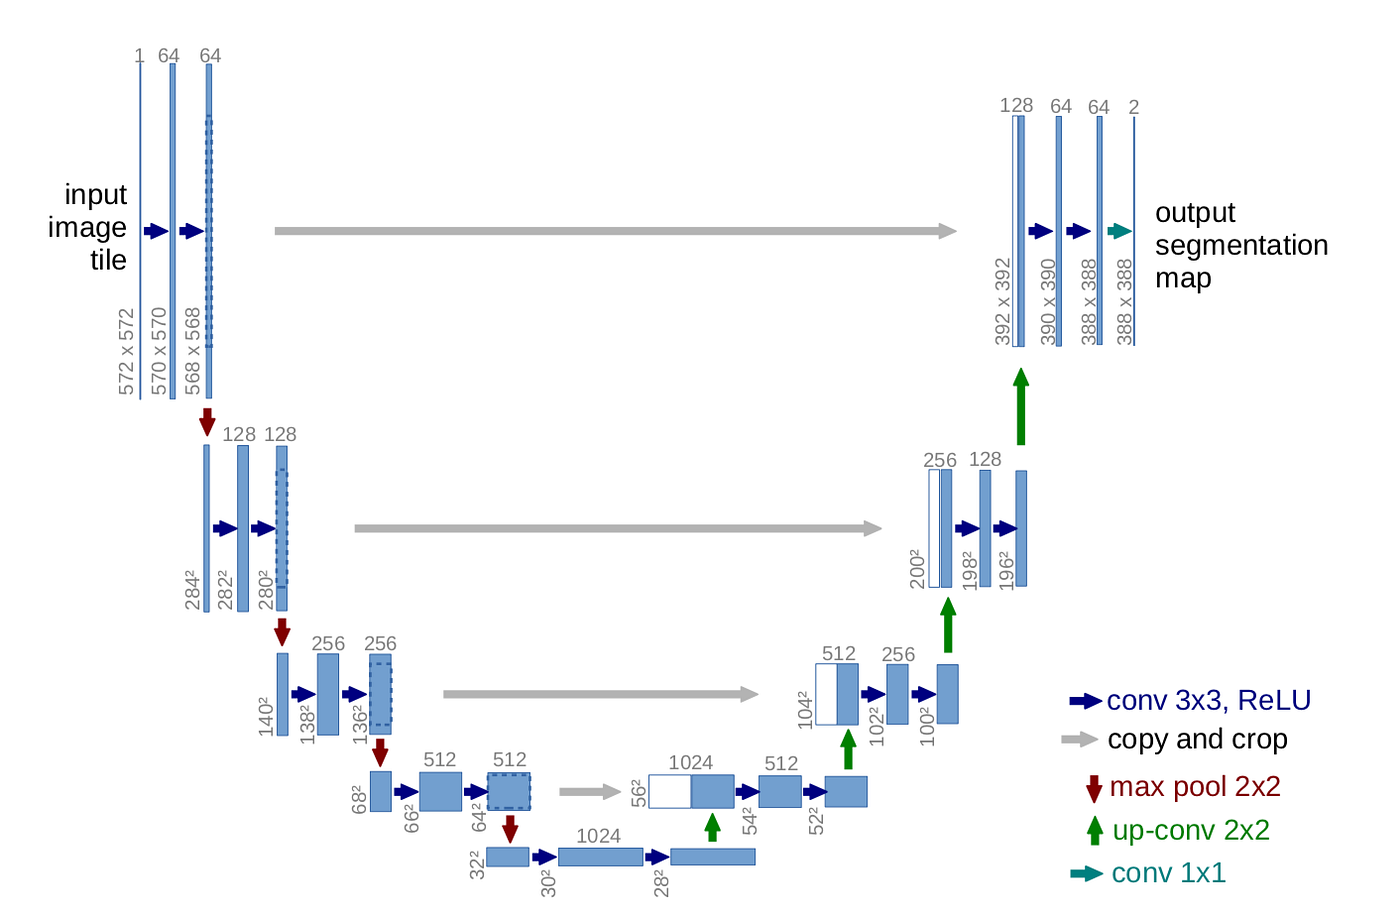

In [ ]:
class BloqueConv(nn.Sequential):
    """Dos veces (convolución 3x3 -> BatchNorm -> ReLU)."""
    def __init__(self, c_in, c_out):
        super().__init__(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        )

class UNet(nn.Module):
    def __init__(self, c_in=1, c_out=1, base=32):
        super().__init__()
        canales = [base, base * 2, base * 4, base * 8]

        # Encoder
        self.encoders = nn.ModuleList()
        c = c_in
        for ch in canales:
            self.encoders.append(BloqueConv(c, ch))
            c = ch
        self.pool = nn.MaxPool2d(2)

        # Cuello de botella
        self.cuello = BloqueConv(c, c * 2)
        c = c * 2

        # Decoder
        self.subidas = nn.ModuleList()
        self.decoders = nn.ModuleList()
        for ch in reversed(canales):
            self.subidas.append(nn.ConvTranspose2d(c, ch, kernel_size=2, stride=2))
            self.decoders.append(BloqueConv(ch * 2, ch))   # ch*2 porque concatenamos el salto
            c = ch

        self.salida = nn.Conv2d(c, c_out, kernel_size=1)

    def forward(self, x):
        saltos = []
        for enc in self.encoders:
            x = enc(x)
            saltos.append(x)          # guardamos para la conexión de salto
            x = self.pool(x)
        x = self.cuello(x)
        for subir, dec, salto in zip(self.subidas, self.decoders, reversed(saltos)):
            x = subir(x)
            x = dec(torch.cat([x, salto], dim=1))
        return self.salida(x)         # logits: todavía sin sigmoide

modelo = UNet().to(device)
with torch.no_grad():
    prueba = modelo(torch.zeros(2, 1, TAM, TAM, device=device))
n_params = sum(p.numel() for p in modelo.parameters())
print("Forma de la salida:", tuple(prueba.shape), f"| parámetros: {n_params / 1e6:.1f} M")

Forma de la salida: (2, 1, 256, 256) | parámetros: 7.8 M


## **7. FUNCIÓN DE PÉRDIDA Y EVALUACIÓN**

Combinamos dos pérdidas:
- **BCE** (entropía cruzada binaria): evalúa cada píxel por separado; da gradientes estables.
- **Dice**: evalúa el solapamiento global; no se deja engañar por el desbalance entre fondo y bazo.

Para **evaluar** hacemos lo que se hace en la práctica clínica: predecimos **todos** los cortes de un paciente, armamos el volumen 3D y calculamos un Dice por paciente.

In [ ]:
def perdida_dice(logits, y, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * y).sum(dim=(1, 2, 3))
    total = p.sum(dim=(1, 2, 3)) + y.sum(dim=(1, 2, 3))
    return 1 - ((2 * inter + eps) / (total + eps)).mean()

def perdida(logits, y):
    return F.binary_cross_entropy_with_logits(logits, y) + perdida_dice(logits, y)

@torch.no_grad()
def predecir_paciente(p, lote=32):
    """Segmenta todos los cortes de un paciente. Devuelve un volumen (Z, H, W) de 0/1."""
    modelo.eval()
    vol = torch.from_numpy(datos[p]["img"]).unsqueeze(1)        # (Z, 1, H, W) uint8
    partes = []
    for k in range(0, len(vol), lote):
        logits = modelo(vol[k : k + lote].float().div(255.0).to(device))
        partes.append((logits > 0).squeeze(1).cpu().numpy())     # logit > 0  <=>  probabilidad > 0.5
    return np.concatenate(partes).astype(np.uint8)

def evaluar(lista_pacientes):
    """Dice 3D de cada paciente de la lista."""
    return np.array([dice_np(predecir_paciente(p), datos[p]["mask"]) for p in lista_pacientes])

## **8. Entrenamiento**

En cada época: pasamos por todos los lotes de entrenamiento, luego medimos el Dice 3D en los pacientes de validación y guardamos el modelo si mejoró.

In [ ]:
EPOCAS = 15
LR = 1e-3

optimizador = torch.optim.Adam(modelo.parameters(), lr=LR)
planificador = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=EPOCAS)

historia = {"perdida": [], "dice": []}
mejor_dice = -1.0

for epoca in range(1, EPOCAS + 1):
    modelo.train()
    acumulada = 0.0
    for x, y in dl_train:
        x, y = x.to(device), y.to(device)
        optimizador.zero_grad()
        loss = perdida(modelo(x), y)
        loss.backward()
        optimizador.step()
        acumulada += loss.item()
    planificador.step()

    dice_val = evaluar(pac_val).mean()
    historia["perdida"].append(acumulada / len(dl_train))
    historia["dice"].append(dice_val)

    marca = ""
    if dice_val > mejor_dice:
        mejor_dice = dice_val
        torch.save(modelo.state_dict(), "mejor_modelo.pt")
        marca = "  <- guardado"
    print(f"Época {epoca:02d}/{EPOCAS} | pérdida de entrenamiento {historia['perdida'][-1]:.3f} | "
          f"Dice 3D en validación {dice_val:.3f}{marca}")

Época 01/15 | pérdida de entrenamiento 1.408 | Dice 3D en validación 0.000  <- guardado
Época 02/15 | pérdida de entrenamiento 1.177 | Dice 3D en validación 0.000
Época 03/15 | pérdida de entrenamiento 1.027 | Dice 3D en validación 0.565  <- guardado
Época 04/15 | pérdida de entrenamiento 0.852 | Dice 3D en validación 0.808  <- guardado
Época 05/15 | pérdida de entrenamiento 0.714 | Dice 3D en validación 0.829  <- guardado
Época 06/15 | pérdida de entrenamiento 0.636 | Dice 3D en validación 0.896  <- guardado
Época 07/15 | pérdida de entrenamiento 0.589 | Dice 3D en validación 0.924  <- guardado
Época 08/15 | pérdida de entrenamiento 0.571 | Dice 3D en validación 0.768
Época 09/15 | pérdida de entrenamiento 0.564 | Dice 3D en validación 0.885
Época 10/15 | pérdida de entrenamiento 0.547 | Dice 3D en validación 0.924  <- guardado
Época 11/15 | pérdida de entrenamiento 0.540 | Dice 3D en validación 0.915
Época 12/15 | pérdida de entrenamiento 0.537 | Dice 3D en validación 0.909
Época 13/

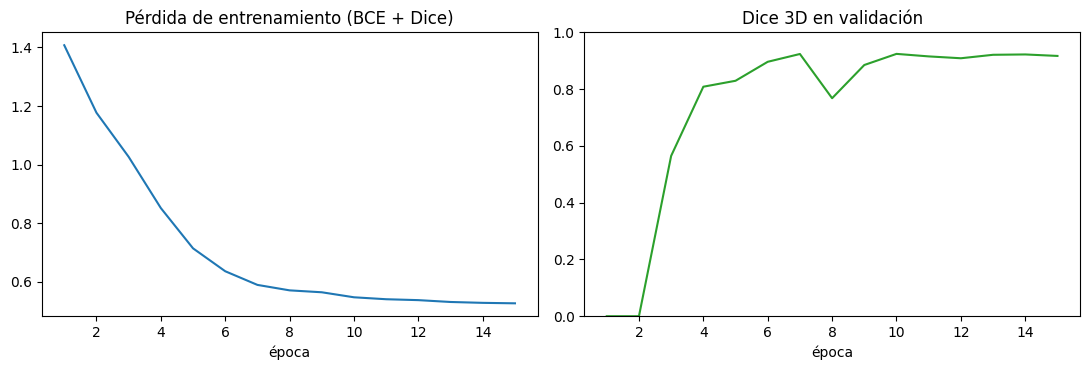

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(range(1, EPOCAS + 1), historia["perdida"])
ax[0].set_xlabel("época"); ax[0].set_title("Pérdida de entrenamiento (BCE + Dice)")
ax[1].plot(range(1, EPOCAS + 1), historia["dice"], color="tab:green")
ax[1].set_xlabel("época"); ax[1].set_title("Dice 3D en validación"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

In [ ]:
modelo.load_state_dict(torch.load("mejor_modelo.pt", map_location=device))
pred_test = {p: predecir_paciente(p) for p in pac_test}
dice_test = np.array([dice_np(pred_test[p], datos[p]["mask"]) for p in pac_test])

print(f"{'Paciente':<22}{'Dice U-Net':>12}{'Dice umbral':>14}")
for p, d_red, d_umb in zip(pac_test, dice_test, dice_umbral):
    print(f"{p:<22}{d_red:>12.3f}{d_umb:>14.3f}")
print(f"{'PROMEDIO':<22}{dice_test.mean():>12.3f}{dice_umbral.mean():>14.3f}")

Paciente                Dice U-Net   Dice umbral
spleen_20.nii.gz             0.957         0.089
spleen_14.nii.gz             0.971         0.084
spleen_21.nii.gz             0.952         0.054
spleen_61.nii.gz             0.942         0.030
spleen_44.nii.gz             0.920         0.023
spleen_41.nii.gz             0.918         0.036
PROMEDIO                     0.943         0.053


## **9. Evaluación en los pacientes de prueba**

Cargamos el mejor modelo y lo medimos sobre pacientes que nunca vio, ni para entrenar ni para elegir el modelo.

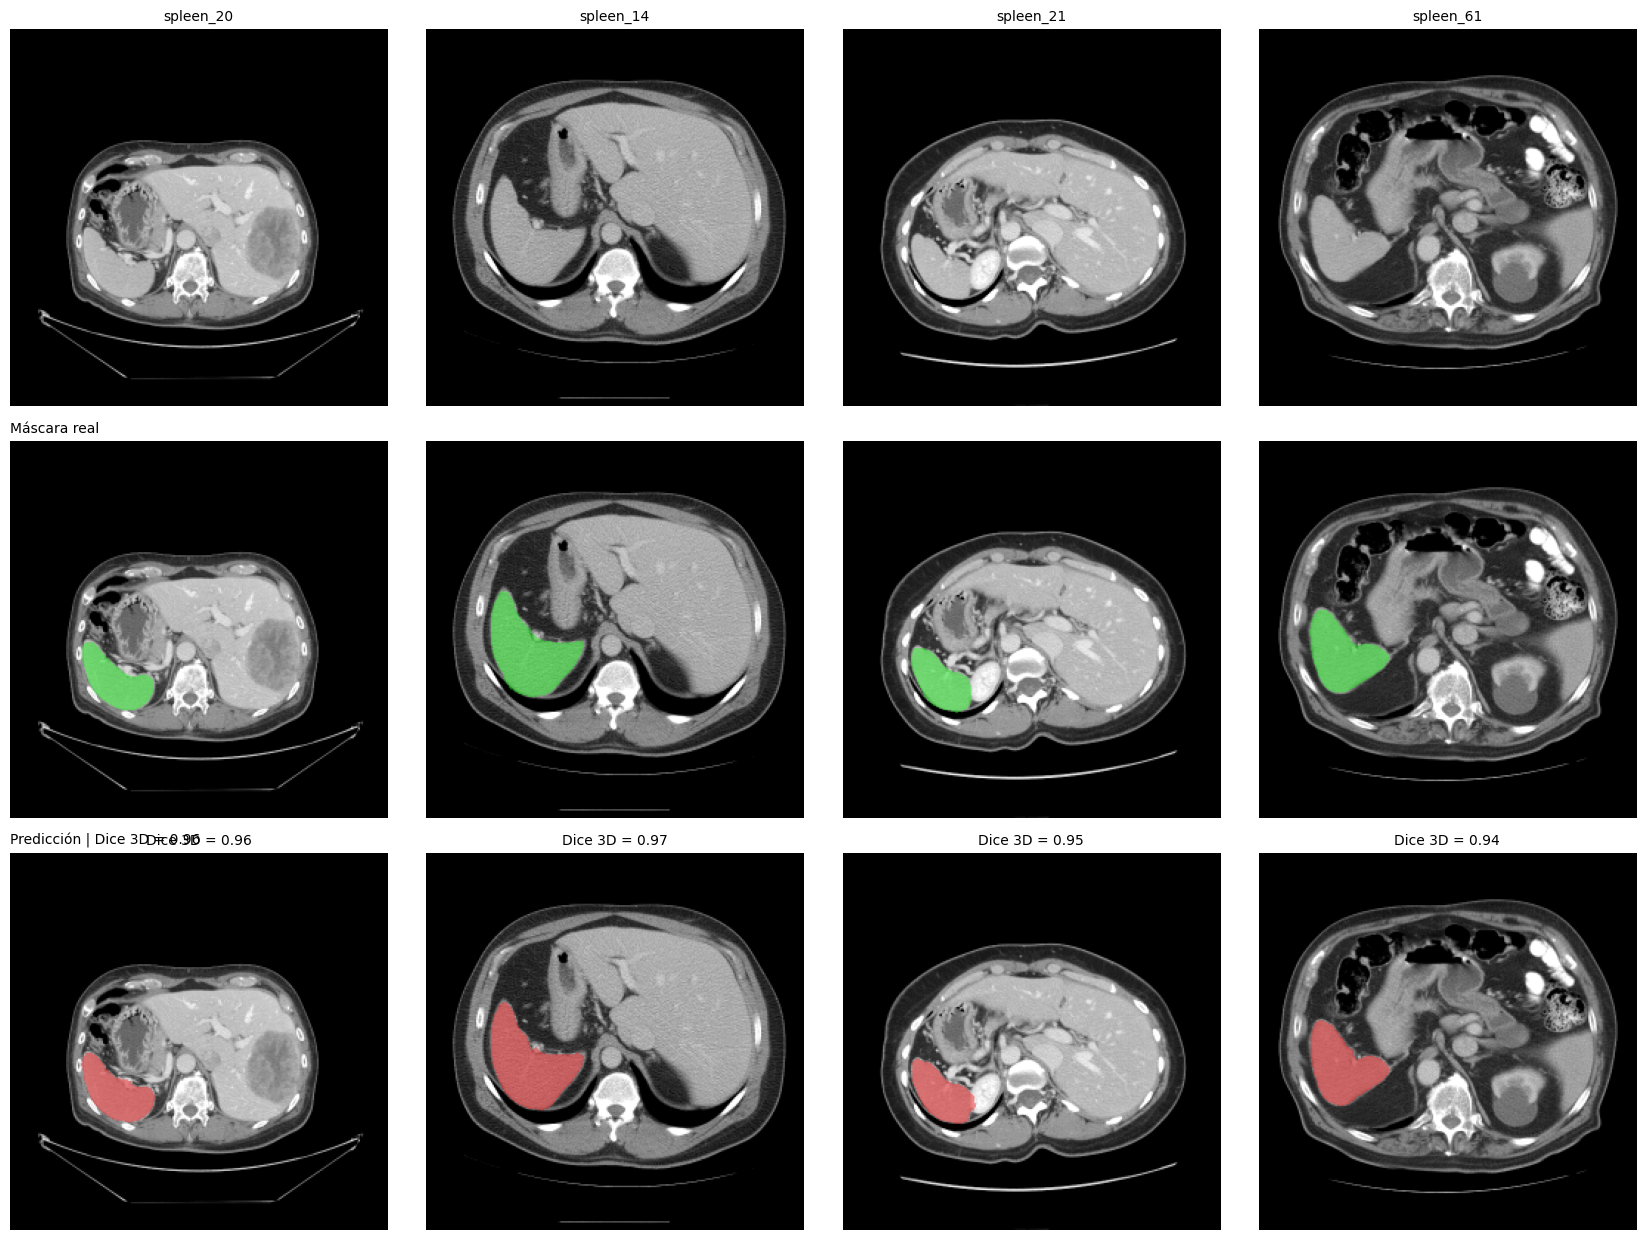

In [ ]:
# Verde = máscara real, rojo = predicción de la red. Para cada paciente mostramos el corte con más bazo.
n = min(4, len(pac_test))
fig, ax = plt.subplots(3, n, figsize=(4.2 * n, 12.5), squeeze=False)
for j, p in enumerate(pac_test[:n]):
    k = int(datos[p]["mask"].sum(axis=(1, 2)).argmax())
    img = datos[p]["img"][k]
    ax[0, j].imshow(img, cmap="gray")
    ax[0, j].set_title(p.replace(".nii.gz", ""), fontsize=10)
    ax[1, j].imshow(superponer(img, datos[p]["mask"][k], color=(0, 255, 0)))
    ax[2, j].imshow(superponer(img, pred_test[p][k], color=(255, 0, 0)))
    ax[2, j].set_title(f"Dice 3D = {dice_test[j]:.2f}", fontsize=10)
ax[1, 0].set_title("Máscara real", loc="left", fontsize=10)
ax[2, 0].set_title(f"Predicción | Dice 3D = {dice_test[0]:.2f}", loc="left", fontsize=10)
for a in ax.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

## **10. Posprocesamiento: quedarse con el componente más grande**

La red trabaja corte por corte y a veces marca pequeñas "islas" lejos del bazo. Pero sabemos algo de anatomía: **hay un solo bazo y es una pieza conectada**. Si nos quedamos solo con la región 3D conectada más grande, eliminamos esos falsos positivos.

In [ ]:
from scipy import ndimage

def componente_mayor(vol):
    """Conserva solo la región 3D conectada más grande de un volumen binario."""
    etiquetas, n = ndimage.label(vol)
    if n <= 1:
        return vol
    tamanos = ndimage.sum(vol, etiquetas, index=range(1, n + 1))
    return (etiquetas == (1 + int(np.argmax(tamanos)))).astype(np.uint8)

pred_post = {p: componente_mayor(pred_test[p]) for p in pac_test}
dice_post = np.array([dice_np(pred_post[p], datos[p]["mask"]) for p in pac_test])
print(f"Dice promedio sin posprocesar: {dice_test.mean():.3f}")
print(f"Dice promedio con componente mayor: {dice_post.mean():.3f}")

Dice promedio sin posprocesar: 0.943
Dice promedio con componente mayor: 0.951


## **11. De la máscara a una medida clínica: el volumen del bazo**

Segmentar no es el objetivo final. Con la máscara y el tamaño del vóxel se puede calcular el **volumen del órgano**, que sirve, por ejemplo, para detectar esplenomegalia (bazo agrandado).

Volumen = número de vóxeles marcados × volumen de un vóxel.

In [ ]:
print(f"{'Paciente':<22}{'Real (mL)':>12}{'Predicho (mL)':>16}{'Error':>9}")
for p in pac_test:
    real = datos[p]["mask"].sum() * datos[p]["ml"]
    predicho = pred_post[p].sum() * datos[p]["ml"]
    print(f"{p:<22}{real:>12.0f}{predicho:>16.0f}{100 * (predicho - real) / real:>8.1f}%")

Paciente                 Real (mL)   Predicho (mL)    Error
spleen_20.nii.gz               284             290     2.3%
spleen_14.nii.gz               443             457     3.1%
spleen_21.nii.gz               130             128    -1.8%
spleen_61.nii.gz               161             161     0.3%
spleen_44.nii.gz               117             124     6.1%
spleen_41.nii.gz               186             180    -3.0%
